In [1]:
import os
import pandas as pd
import matplotlib.pyplot as plt

plt.rcParams.update({
    "font.size": 16,          # default text
    "axes.labelsize": 18,     # x- and y-axis labels
    "axes.titlesize": 18,     # plot title
    "xtick.labelsize": 17,    # x-axis tick labels
    "ytick.labelsize": 17,    # y-axis tick labels
    "legend.fontsize": 18,    # legend labels
    "legend.title_fontsize": 16,
})

TOOL_COLUMNS = ["DL4PatchCorrectness", "LLM4PatchCorrectness", "Invalidator", "entropy_delta", "FIXCHECK"]
BASELINE_COLUMNS = ["RS-85", "RS-95"]

# Display names used for graph legends/labels.
TOOL_DISPLAY_NAMES = {
    "DL4PatchCorrectness": "Tian et al.",
    "LLM4PatchCorrectness": "LLM4PatchCorrect",
    "Invalidator": "Invalidator",
    "entropy_delta": "Yang et al.",
    "FIXCHECK": "FIXCHECK",
}

# Distinct color/marker/linestyle per tool so overlapping lines stay distinguishable.
TOOL_STYLES = {
    "DL4PatchCorrectness": {"color": "tab:blue", "marker": "v", "linestyle": (0, (3, 1, 1, 1))},
    "LLM4PatchCorrectness": {"color": "tab:red", "marker": "D", "linestyle": ":"},
    "Invalidator": {"color": "tab:green", "marker": "s", "linestyle": "--"},
    "entropy_delta": {"color": "tab:purple", "marker": "o", "linestyle": "-"},
    "FIXCHECK": {"color": "tab:orange", "marker": "^", "linestyle": "-."},
}

In [2]:
def compute_sensitivity(df, min_overfitting=1, min_total=10):
    """For bugs with >= min_overfitting overfitting patches and >= min_total total patches,
    count how often each RS baseline matches or outperforms (i.e. needs to inspect
    the same number or fewer patches than) each POD tool. A tool's N/A entries are
    treated as the worst case (patch_num_total), since the tool never surfaced a
    correct patch. Returns (wins, n_bugs) where wins is {baseline: {tool: count}}."""
    filtered = df[(df["patch_num_overfitting"] >= min_overfitting) & (df["patch_num_total"] >= min_total)]
    n_bugs = len(filtered)
    wins = {baseline: {} for baseline in BASELINE_COLUMNS}
    for baseline in BASELINE_COLUMNS:
        for tool in TOOL_COLUMNS:
            tool_values = filtered[tool].fillna(filtered["patch_num_total"])
            wins[baseline][tool] = int((filtered[baseline] <= tool_values).sum())
    return wins, n_bugs

def sensitivity_analysis(df, min_overfitting=1, min_total=10):
    wins, n_bugs = compute_sensitivity(df, min_overfitting=min_overfitting, min_total=min_total)
    print(f"Bugs with >= {min_overfitting} overfitting patch(es) and >= {min_total} total patches: {n_bugs}")
    for baseline, tool_wins in wins.items():
        print(f"\n{baseline} matches or outperforms:")
        for tool, count in sorted(tool_wins.items(), key=lambda item: item[1]):
            pct = count / n_bugs * 100 if n_bugs else 0
            print(f"  {tool}: {count} / {n_bugs} bugs ({pct:.1f}%)")

In [ ]:
def plot_sensitivity(df, thresholds=range(10, 61, 10), min_overfitting=1, save_name=None, include_legend=True):
    """Plot, for each baseline, the % of qualifying bugs it matches/outperforms
    each POD tool on, as the minimum total-patches-per-bug threshold increases."""
    records = []
    for min_total in thresholds:
        wins, n_bugs = compute_sensitivity(df, min_overfitting=min_overfitting, min_total=min_total)
        for baseline, tool_wins in wins.items():
            for tool, count in tool_wins.items():
                pct = count / n_bugs * 100 if n_bugs else float("nan")
                records.append({"min_total": min_total, "baseline": baseline, "tool": tool, "pct": pct, "n_bugs": n_bugs})
    plot_df = pd.DataFrame(records)

    # Small per-tool vertical offset keeps exactly-overlapping lines visible.
    jitter_step = 0.6
    jitter_by_tool = {tool: (i - (len(TOOL_COLUMNS) - 1) / 2) * jitter_step for i, tool in enumerate(TOOL_COLUMNS)}

    plot_height = 5.5
    legend_height = 0.45 if include_legend else 0
    figure_height = plot_height + legend_height

    fig, axes = plt.subplots(
        1,
        len(BASELINE_COLUMNS),
        figsize=(7 * len(BASELINE_COLUMNS), figure_height),
        sharey=True,
    )
    for ax, baseline in zip(axes, BASELINE_COLUMNS):
        subset = plot_df[plot_df["baseline"] == baseline]
        for tool in TOOL_COLUMNS:
            tool_subset = subset[subset["tool"] == tool]
            style = TOOL_STYLES[tool]
            ax.plot(
                tool_subset["min_total"],
                tool_subset["pct"] + jitter_by_tool[tool],
                label=TOOL_DISPLAY_NAMES[tool],
                linewidth=2,
                markersize=10,
                markeredgecolor="white",
                markeredgewidth=0.6,
                alpha=0.9,
                **style,
            )
        n_bugs_per_threshold = subset.drop_duplicates("min_total").set_index("min_total")["n_bugs"]
        ax.set_xticks(list(thresholds))
        ax.set_xticklabels([f"{t}\n(n={n_bugs_per_threshold[t]})" for t in thresholds])
        ax.set_xlabel("Min total patches per bug")
        # ax.set_ylabel("% of bugs matched/outperformed by {}".format(baseline))
        ax.set_ylabel("% of bugs matched/outperformed")
        ax.set_ylim(0, 105)
        ax.set_title(f"{baseline} vs. POD tools")
        ax.tick_params(axis="y")
        ax.grid(True, axis="y", linestyle=":", alpha=0.4)

    if include_legend:
        handles, labels = axes[0].get_legend_handles_labels()
        legend_fraction = legend_height / figure_height

        fig.legend(
            handles,
            labels,
            loc="lower center",
            bbox_to_anchor=(0.5, 0.0),
            ncol=len(TOOL_COLUMNS),
            frameon=True,
        )
        fig.tight_layout(rect=(0, legend_fraction, 1, 1))
    else:
        fig.tight_layout()

    if save_name:
        fig.savefig(f"{save_name}.png", dpi=300)
    plt.show()
    return plot_df


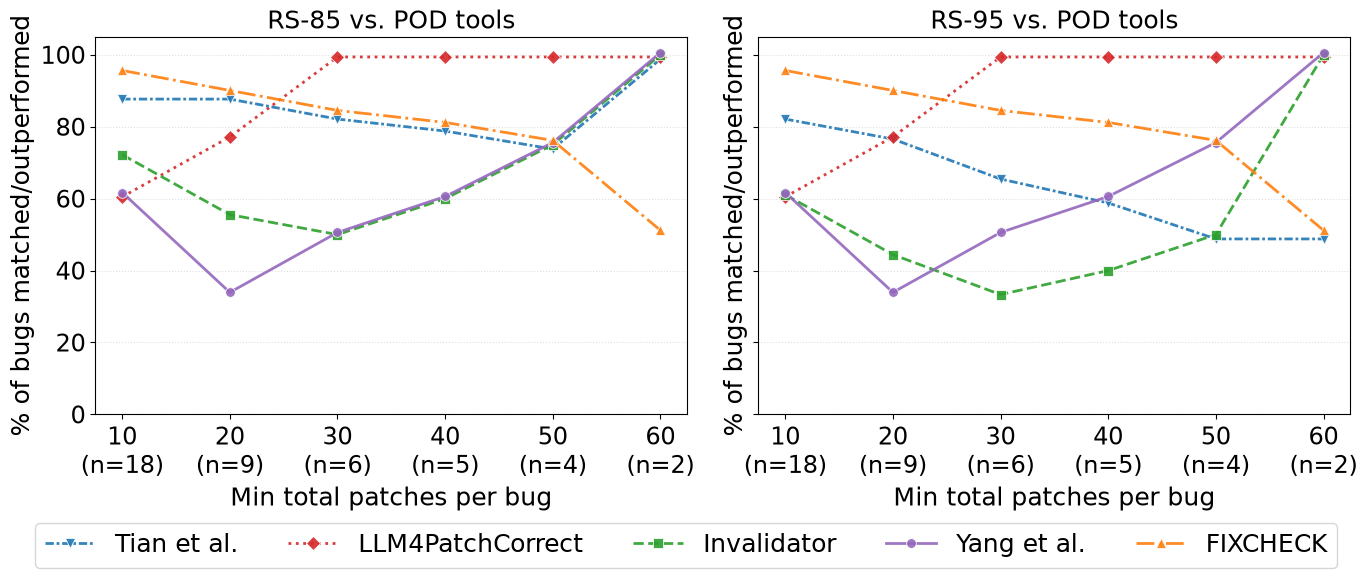


Results for min_total=10:
Bugs with >= 0 overfitting patch(es) and >= 10 total patches: 18

RS-85 matches or outperforms:
  LLM4PatchCorrectness: 11 / 18 bugs (61.1%)
  entropy_delta: 11 / 18 bugs (61.1%)
  Invalidator: 13 / 18 bugs (72.2%)
  DL4PatchCorrectness: 16 / 18 bugs (88.9%)
  FIXCHECK: 17 / 18 bugs (94.4%)

RS-95 matches or outperforms:
  LLM4PatchCorrectness: 11 / 18 bugs (61.1%)
  Invalidator: 11 / 18 bugs (61.1%)
  entropy_delta: 11 / 18 bugs (61.1%)
  DL4PatchCorrectness: 15 / 18 bugs (83.3%)
  FIXCHECK: 17 / 18 bugs (94.4%)

Results for min_total=20:
Bugs with >= 0 overfitting patch(es) and >= 20 total patches: 9

RS-85 matches or outperforms:
  entropy_delta: 3 / 9 bugs (33.3%)
  Invalidator: 5 / 9 bugs (55.6%)
  LLM4PatchCorrectness: 7 / 9 bugs (77.8%)
  DL4PatchCorrectness: 8 / 9 bugs (88.9%)
  FIXCHECK: 8 / 9 bugs (88.9%)

RS-95 matches or outperforms:
  entropy_delta: 3 / 9 bugs (33.3%)
  Invalidator: 4 / 9 bugs (44.4%)
  DL4PatchCorrectness: 7 / 9 bugs (77.8%)
  L

In [4]:
def overall_analysis(dataset_dir, plot_min=1, plot_max=9,plot_increment=1, individual_results=None, include_legend=True):
    """
    dataset_dir = any of "combined_figures", "petke_1h_figures", "petke_8h_figures", "repairllama_figures", "repairllama_dedup_figures"
    """
    csv_path = os.path.join("..", "figure_replication", dataset_dir, "tables", "rq3", "rs-combined.csv")
    
    df = pd.read_csv(csv_path)
    df = df.iloc[:-1] # drop Overall row

    # Extract correct/overfitting patch counts from the "Bug" column, e.g. "Chart-1 (1:7)"
    counts = df["Bug"].str.extract(r"\((\d+):(\d+)\)").astype(int)
    df["patch_num_correct"] = counts[0]
    df["patch_num_overfitting"] = counts[1]
    df["patch_num_total"] = df["patch_num_correct"] + df["patch_num_overfitting"]

    plot_sensitivity(df, thresholds=range(plot_min, plot_max+1, plot_increment), min_overfitting=0, save_name=f"sensitivity_{dataset_dir}", include_legend=include_legend)

    if individual_results is not None:
        for min_total in range(plot_min, plot_max+1, plot_increment):
            print(f"\nResults for min_total={min_total}:")
            sensitivity_analysis(df, min_overfitting=0, min_total=min_total)

overall_analysis("petke_8h_figures", plot_min=10, plot_max=60, plot_increment=10, individual_results=[10, 20], include_legend=True)


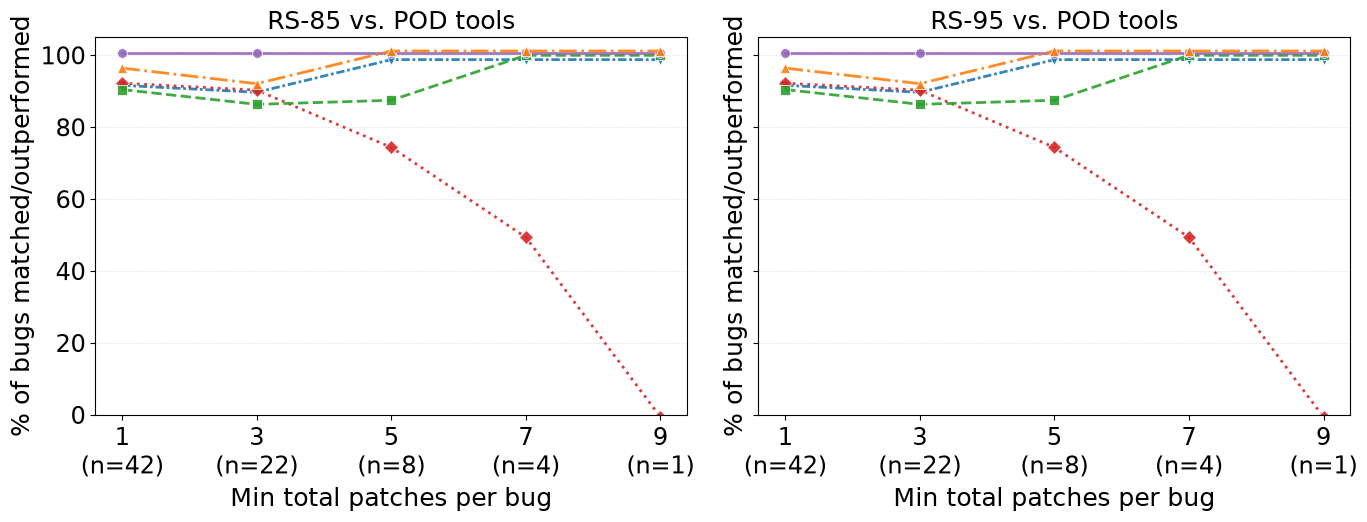

In [5]:
overall_analysis("repairllama_dedup_figures", plot_min=1, plot_max=9, plot_increment=2, include_legend=False)